# How far can the M2-4 reference be trusted? Uncertainty of the M2-3 gain pattern

`reconstruct_m2_3_pattern.py` transfers gain from Meteor-M N2-4 to N2-3. The unknown receiver constant cancels, so the M2-3
pattern inherits the absolute scale of `m2_4_pattern.csv`. That transfer assumes the **in-flight M2-4 antenna is
axisymmetric and nadir-pointing**, exactly as the reference describes (uncertainty source 4 in the metadata).
The pipeline's hold-out closure test says this is only true to about ±1–2 dB: M2-4 reads high on its starboard side and
low on its port side.

This notebook turns that into a per-cell uncertainty for the M2-3 pattern:

1. **Hold-out residual** (model-free): calibrate on half of the M2-4 passes and compare the other half with the reference.
2. **Deviation map `D`**: jointly fit the receiver response (ground-station frame), M2-4's deviation from its reference
   (M2-4 body frame) and a per-pass offset.
3. **Transfer error**: rebuild the M2-3 pattern with `D` removed from the calibration; the change is the error the
   published pattern carries from source 4.
4. **Statistical scatter**: bootstrap over passes of both satellites.
5. **Combined per-cell uncertainty**, written to `m2_3_pattern_output/m2_3_gain_uncertainty.csv`.

Sources 1–3 (transmit-power difference, receive-processing difference, reference definition) shift the whole pattern by a
constant or are not observable from these passes; they are listed in `m2_3_pattern_metadata.json` and are **not** included
in the numbers below.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Patch

import reconstruct_m2_3_pattern as rp

# ---- Configuration -------------------------------------------------------------------------------------
OUT_DIR = rp.OUTPUT_DIR
GAIN = rp.GAIN_COLUMN  # e.g. "gain_dbic"

# M2-4 deviation map D: coarser than the 1-deg output grid, because D is smooth and its noise is
# dominated by pass-to-pass offsets, so each bin needs several passes.
D_AZ_BIN_DEG = 10.0
D_TH_BIN_DEG = 2.0
D_MIN_OFF_NADIR_DEG = 10.0  # body azimuth is poorly defined close to nadir
D_MIN_SAMPLES = 100
D_MIN_TRACKS = 3
MAX_ITER = 150  # alternating-median fit
TOL_DB = 0.02

N_BOOT = 40  # bootstrap replicates (each ~2.5 s)
BOOT_MIN_FINITE = 0.5  # a cell needs a value in >= 50% of replicates to get a bootstrap sigma
SEED = 20261028

# ---- Plot style ----------------------------------------------------------------------------------------------
MISSING = "#a3a29c"  # unsupported / not estimated
DIVERGING = "RdBu_r"  # red = positive, blue = negative, near-white = 0
SEQUENTIAL = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.12, 1.0, 256)))
RING_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load both satellites with the pipeline's own validation and geometry

Same rejection rules, sample-time geometry interpolation and body frame as the published pattern.
`rx_response_db` is the stage-1 calibration sample `R = p4 - G_ref(theta) - L(d)` for each M2-4 sample.

In [2]:
t0 = time.time()
r_gs = rp.geodetic_to_ecef(rp.GS_LAT_DEG, rp.GS_LON_DEG, rp.GS_ALT_M)
enu = rp.enu_basis(rp.GS_LAT_DEG, rp.GS_LON_DEG)
ref = rp.load_reference_pattern(rp.M2_4_PATTERN_PATH)

m24, *_ = rp.prepare_satellite("m2_4", rp.DATA_DIR, r_gs, enu, need_heading=True)
m24 = rp.receiver_response_samples(m24, ref)
m24 = m24.loc[
    m24["ref_gain_db"].notna() & (m24["heading_status"] != "invalid"),
    ["file", "obs_number", "gs_az_deg", "gs_alt_deg", "azimuth_deg", "off_nadir_deg", "rx_response_db"],
].reset_index(drop=True)

m23, *_ = rp.prepare_satellite("m2_3", rp.DATA_DIR, r_gs, enu, need_heading=True)
m23 = m23[["file", "gs_az_deg", "gs_alt_deg", "range_m", "power_db", "azimuth_deg", "off_nadir_deg", "heading_status"]]

print(f"M2-4: {len(m24):,} calibration samples from {m24['file'].nunique()} passes")
print(f"M2-3: {len(m23):,} samples from {m23['file'].nunique()} passes   (loaded in {time.time() - t0:.0f} s)")

M2-4: 1,862,491 calibration samples from 333 passes
M2-3: 1,874,274 samples from 334 passes   (loaded in 25 s)


In [3]:
N_TH, N_AZ = len(rp.GRID_OFF_NADIR_DEG), len(rp.GRID_AZIMUTH_DEG)
GRID_AZ_EDGES = np.r_[rp.GRID_AZIMUTH_DEG - 0.5, rp.GRID_AZIMUTH_DEG[-1] + 0.5]
GRID_R_EDGES = np.clip(
    np.r_[rp.GRID_OFF_NADIR_DEG - 0.5, rp.GRID_OFF_NADIR_DEG[-1] + 0.5], 0, rp.GRID_OFF_NADIR_DEG[-1]
)
N_DAZ = int(360 / D_AZ_BIN_DEG)
N_DTH = int(np.ceil((rp.GRID_OFF_NADIR_DEG[-1] + 1) / D_TH_BIN_DEG))
D_AZ_EDGES = np.arange(N_DAZ + 1) * D_AZ_BIN_DEG
D_R_EDGES = np.minimum(np.arange(N_DTH + 1) * D_TH_BIN_DEG, rp.GRID_OFF_NADIR_DEG[-1])


def reconstruct_grid(m24_part, m23_part):
    # Pipeline stages 1-3: M2-4 calibration map -> M2-3 per-sample gain -> 1-deg body-frame grid.
    rx = rp.build_receiver_map(m24_part)
    g3 = rp.reconstruct_m23_gain(m23_part, rx)
    ok = g3["gain_db"].notna() & (g3["heading_status"] != "invalid")
    ok &= np.rint(g3["off_nadir_deg"]) <= rp.GRID_OFF_NADIR_DEG[-1]
    grid, _ = rp.build_body_frame_grid(g3[ok])
    return grid


def body_bin(az_deg, th_deg):
    # Code of the D bin (D_TH_BIN_DEG x D_AZ_BIN_DEG) holding each body-frame direction.
    return np.floor(np.asarray(th_deg) / D_TH_BIN_DEG).astype(int) * N_DAZ + (
        np.floor(np.asarray(az_deg) / D_AZ_BIN_DEG).astype(int) % N_DAZ
    )


def bins_to_2d(values_by_bin):
    # Series indexed by bin code -> (N_DTH, N_DAZ) array, NaN where absent.
    out = np.full(N_DTH * N_DAZ, np.nan)
    idx = values_by_bin.index.to_numpy()
    keep = idx < out.size
    out[idx[keep]] = values_by_bin.to_numpy()[keep]
    return out.reshape(N_DTH, N_DAZ)


def polar_map(ax, z, az_edges, r_edges, cmap, norm, title):
    # Body-frame polar map, viewed from above the satellite: forward up, +y_b (starboard) right.
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    theta = np.radians(az_edges)
    ax.pcolormesh(
        theta,
        r_edges,
        np.where(np.isnan(z), 1.0, np.nan),
        cmap=ListedColormap([MISSING]),
        vmin=0,
        vmax=1,
        shading="flat",
    )
    mesh = ax.pcolormesh(theta, r_edges, np.ma.masked_invalid(z), cmap=cmap, norm=norm, shading="flat")
    ax.set_ylim(0, rp.GRID_OFF_NADIR_DEG[-1])
    ax.set_yticks([15, 30, 45, 60])
    ax.set_yticklabels(["15°", "30°", "45°", "60°"], fontsize=7, color="#52514e")
    ax.set_xticks(np.radians([0, 90, 180, 270]))
    ax.set_xticklabels(["fwd", "starboard\n+y_b", "aft", "port\n-y_b"], fontsize=8)
    ax.tick_params(axis="x", pad=4)
    ax.grid(color="white", alpha=0.5, linewidth=0.5)
    ax.set_title(title, fontsize=10, pad=16)
    return mesh


MISSING_PATCH = Patch(facecolor=MISSING, label="no estimate")

## 2. Model-free check: hold-out residual in the M2-4 body frame

Split the M2-4 passes by observation-number parity. Build the calibration map from one half and evaluate it for the
other half; then swap. Every M2-4 sample is tested exactly once. Its residual
`R - R_hat_other_half` equals *recovered M2-4 gain minus reference gain*, and should be ~0 everywhere if the reference
holds in flight.

In [4]:
holdout = np.full(len(m24), np.nan)
for parity in (0, 1):
    cal = (m24["obs_number"] % 2 == parity).to_numpy()
    rx = rp.build_receiver_map(m24[cal])
    r_hat, status = rx.interpolator(m24.loc[~cal, "gs_az_deg"].to_numpy(), m24.loc[~cal, "gs_alt_deg"].to_numpy())
    holdout[~cal] = np.where(
        status == rp.GapLimitedLinearInterpolator.OK, m24.loc[~cal, "rx_response_db"].to_numpy() - r_hat, np.nan
    )
m24["holdout_residual_db"] = holdout

b_raw = body_bin(m24["azimuth_deg"].to_numpy(), m24["off_nadir_deg"].to_numpy())
holdout_by_bin = pd.Series(holdout).groupby(b_raw).median()
print(
    f"Hold-out residual over all samples: median {np.nanmedian(holdout):+.2f} dB, "
    f"MAD {np.nanmedian(np.abs(holdout - np.nanmedian(holdout))):.2f} dB"
)

Hold-out residual over all samples: median +0.12 dB, MAD 1.73 dB


## 3. Joint fit: receiver response + M2-4 deviation + pass offsets

Every M2-4 calibration sample is modelled as

$$R_j = A(g_j) + D(b_j) + P(k_j) + \varepsilon_j$$

* `A(g)` — receiver response plus the common constant, on the pipeline's 1° ground-station (azimuth, elevation) grid;
* `D(b)` — **in-flight M2-4 deviation from the reference**, on 10° × 2° bins of the M2-4 body frame (azimuth, off-nadir);
* `P(k)` — a constant offset per pass (ionosphere, pass-level power changes).

`A` and `D` are separable because each patch of sky is seen from different body directions: on ascending vs descending
passes the satellite flies different headings over the same sky direction. The fit alternates medians (robust
back-fitting) until the largest update falls below `TOL_DB`.

**Gauge and identifiability.** Constants can move freely between the terms, so `median(P) = 0` and, in every off-nadir
ring, the median of `D` over azimuth is 0. This is not just bookkeeping. An axisymmetric error in the reference
(a function of off-nadir only) is indistinguishable from the receiver's elevation response, because off-nadir angle and
ground-station elevation are tied together. Likewise, a deviation that looks the same from the ascending and descending
viewpoints of a sky direction is absorbed into `A`. So `D` captures the **azimuthal** part of the M2-4 error that the
data can see, and the transfer error derived from it is a **lower bound** for source 4.

In [5]:
g_code, _ = pd.factorize(
    np.rint(m24["gs_alt_deg"]).astype(int) * 360 + np.mod(np.rint(m24["gs_az_deg"]).astype(int), 360)
)
k_code, track_names = pd.factorize(m24["file"])
b_code, b_values = pd.factorize(b_raw)
n_g, n_k, n_b = g_code.max() + 1, len(track_names), len(b_values)
R = m24["rx_response_db"].to_numpy()

bin_info = (
    pd.DataFrame({"b": b_code, "k": k_code})
    .groupby("b")
    .agg(n_samples=("k", "size"), n_tracks=("k", "nunique"))
    .reindex(range(n_b))
)
bin_info["bin"] = b_values
bin_info["off_nadir_center_deg"] = (b_values // N_DAZ) * D_TH_BIN_DEG + D_TH_BIN_DEG / 2
bin_info["azimuth_center_deg"] = (b_values % N_DAZ) * D_AZ_BIN_DEG + D_AZ_BIN_DEG / 2
fitted = (
    (bin_info["n_samples"] >= D_MIN_SAMPLES)
    & (bin_info["n_tracks"] >= D_MIN_TRACKS)
    & (bin_info["off_nadir_center_deg"] >= D_MIN_OFF_NADIR_DEG)
).to_numpy()
ring = (b_values // N_DAZ)[fitted]


def group_median(x, codes, n):
    return pd.Series(x).groupby(codes).median().reindex(range(n)).to_numpy(copy=True)


D, P = np.zeros(n_b), np.zeros(n_k)
history = []
t0 = time.time()
for _ in range(MAX_ITER):
    A = group_median(R - D[b_code] - P[k_code], g_code, n_g)
    P_new = group_median(R - A[g_code] - D[b_code], k_code, n_k)
    P_new -= np.median(P_new)
    D_new = group_median(R - A[g_code] - P_new[k_code], b_code, n_b)
    D_new[~fitted] = 0.0
    D_new[fitted] -= pd.Series(D_new[fitted]).groupby(ring).transform("median").to_numpy()
    history.append(max(np.abs(D_new - D).max(), np.abs(P_new - P).max()))
    D, P = D_new, P_new
    if history[-1] < TOL_DB:
        break

converged = history[-1] < TOL_DB
print(
    f"{'Converged' if converged else 'Stopped'} after {len(history)} iterations ({time.time() - t0:.0f} s); "
    f"last update {history[-1]:.3f} dB"
)
print(
    f"D estimated in {fitted.sum()} of {n_b} populated bins "
    f"(>= {D_MIN_SAMPLES} samples, >= {D_MIN_TRACKS} passes, off-nadir >= {D_MIN_OFF_NADIR_DEG:g} deg)"
)
Dfit = D[fitted]
print(
    f"M2-4 deviation D: RMS {np.sqrt(np.mean(Dfit**2)):.2f} dB, 5-95% range {np.percentile(Dfit, 5):+.2f} .. "
    f"{np.percentile(Dfit, 95):+.2f} dB"
)
print(f"Pass offsets P: SD {P.std():.2f} dB, 5-95% range {np.percentile(P, 5):+.2f} .. {np.percentile(P, 95):+.2f} dB")

bin_info["deviation_db"] = np.where(fitted, D, np.nan)
bin_info["holdout_residual_db"] = holdout_by_bin.reindex(b_values).to_numpy()
bin_info["fitted"] = fitted

Converged after 95 iterations (18 s); last update 0.019 dB
D estimated in 712 of 1104 populated bins (>= 100 samples, >= 3 passes, off-nadir >= 10 deg)
M2-4 deviation D: RMS 1.22 dB, 5-95% range -2.64 .. +1.46 dB
Pass offsets P: SD 1.86 dB, 5-95% range -3.22 .. +2.96 dB


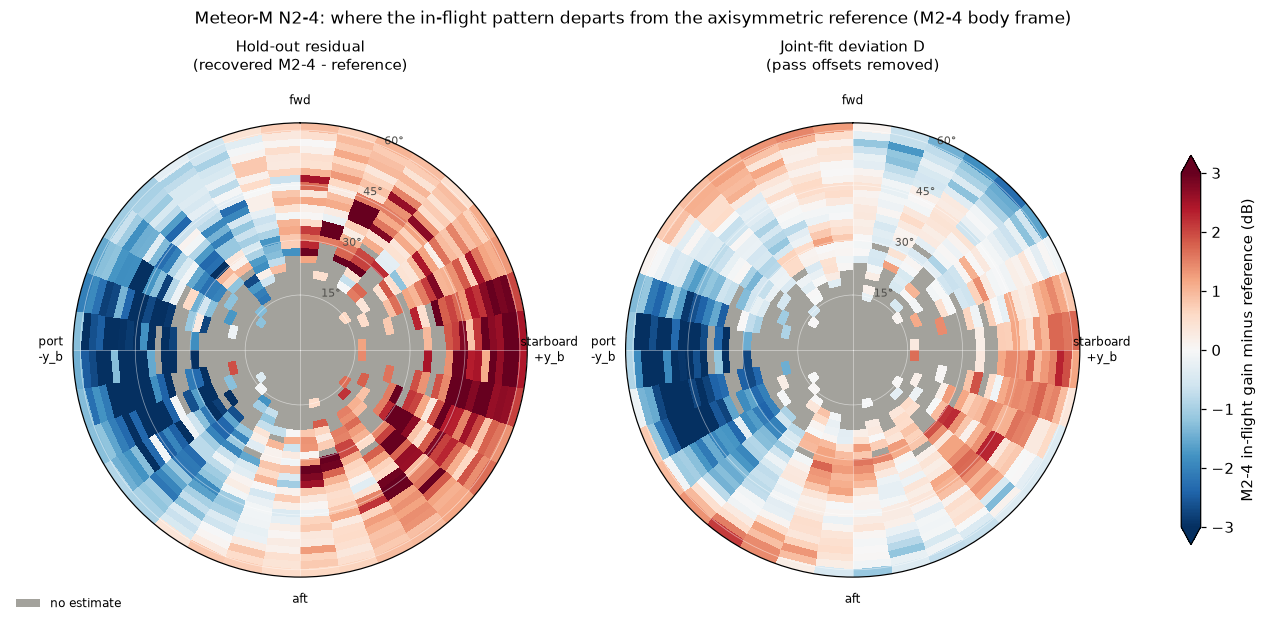

In [6]:
norm = TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.6), subplot_kw={"projection": "polar"}, layout="constrained")
polar_map(
    axes[0],
    bins_to_2d(holdout_by_bin.where(holdout_by_bin.index.isin(b_values[fitted]))),
    D_AZ_EDGES,
    D_R_EDGES,
    DIVERGING,
    norm,
    "Hold-out residual\n(recovered M2-4 - reference)",
)
mesh = polar_map(
    axes[1],
    bins_to_2d(pd.Series(D[fitted], index=b_values[fitted])),
    D_AZ_EDGES,
    D_R_EDGES,
    DIVERGING,
    norm,
    "Joint-fit deviation D\n(pass offsets removed)",
)
cbar = fig.colorbar(mesh, ax=axes, shrink=0.75, extend="both")
cbar.set_label("M2-4 in-flight gain minus reference (dB)")
axes[0].legend(handles=[MISSING_PATCH], loc="upper left", bbox_to_anchor=(-0.15, -0.02), fontsize=8, frameon=False)
fig.suptitle(
    "Meteor-M N2-4: where the in-flight pattern departs from the axisymmetric reference (M2-4 body frame)", fontsize=11
)
plt.show()

The two estimates agree: M2-4 delivers more than the reference toward **starboard** (+y_b) and clearly less toward
**port** (−y_b), with little forward/aft difference. Azimuth profiles through a few off-nadir rings make the size
explicit. The table converts each ring's port/starboard swing (first azimuthal harmonic) into the boresight tilt that
would be needed to produce it with the reference's own slope.

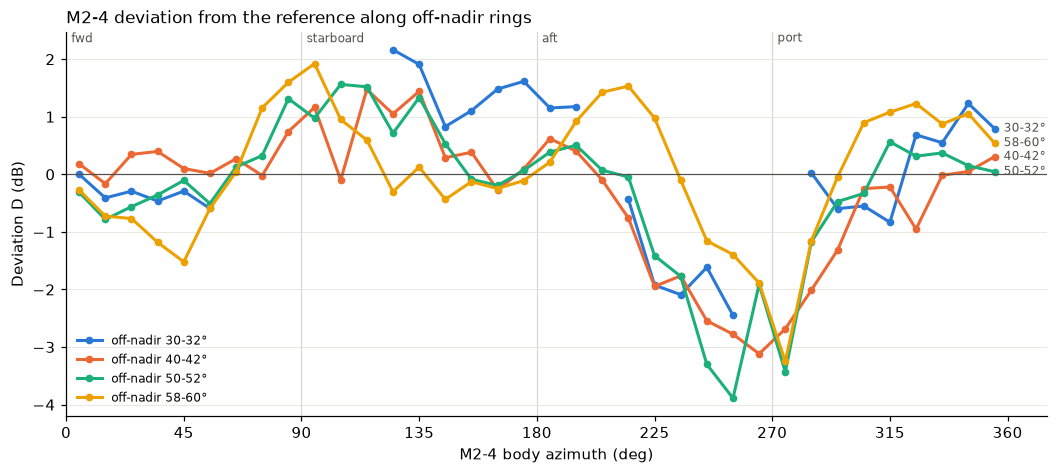

,off-nadir ring,first-harmonic amplitude (dB),"direction of max (body az, deg)",reference slope (dB/deg),tilt needed (deg)
0,30-32°,1.06,105.33,-0.05,21.31
1,40-42°,1.33,89.30,-0.06,20.66
2,50-52°,1.20,92.20,-0.08,15.86
3,58-60°,0.38,112.53,-0.13,2.91


In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4.2), layout="constrained")
az_c = (np.arange(N_DAZ) + 0.5) * D_AZ_BIN_DEG
D2 = bins_to_2d(pd.Series(D[fitted], index=b_values[fitted]))
rows = []
for color, lo in zip(RING_COLORS, (30, 40, 50, 58), strict=True):
    i = int(lo // D_TH_BIN_DEG)
    prof = D2[i]
    ax.plot(az_c, prof, color=color, linewidth=2, marker="o", markersize=4, label=f"off-nadir {lo}-{lo + 2}°")
    last = np.flatnonzero(np.isfinite(prof))[-1]
    ax.annotate(
        f"{lo}-{lo + 2}°",
        (az_c[last], prof[last]),
        xytext=(6, 0),
        textcoords="offset points",
        color="#52514e",
        fontsize=8,
        va="center",
    )
    ok = np.isfinite(prof)
    a, b_ = np.linalg.lstsq(np.c_[np.cos(np.radians(az_c[ok])), np.sin(np.radians(az_c[ok]))], prof[ok], rcond=None)[0]
    th = lo + 1.0
    slope = float((ref(np.array([th + 1.0])) - ref(np.array([th - 1.0])))[0] / 2.0)
    rows.append(
        {
            "off-nadir ring": f"{lo}-{lo + 2}°",
            "first-harmonic amplitude (dB)": np.hypot(a, b_),
            "direction of max (body az, deg)": np.degrees(np.arctan2(b_, a)) % 360,
            "reference slope (dB/deg)": slope,
            "tilt needed (deg)": np.hypot(a, b_) / abs(slope),
        }
    )
ax.axhline(0, color="#52514e", linewidth=0.8)
for x, lab in ((0, "fwd"), (90, "starboard"), (180, "aft"), (270, "port")):
    ax.axvline(x, color="#d8d7d2", linewidth=0.8, zorder=0)
    ax.text(x + 2, ax.get_ylim()[1], lab, color="#52514e", fontsize=8, va="top")
ax.set_xlim(0, 375)
ax.set_xticks(np.arange(0, 361, 45))
ax.set_xlabel("M2-4 body azimuth (deg)")
ax.set_ylabel("Deviation D (dB)")
ax.set_title("M2-4 deviation from the reference along off-nadir rings", fontsize=11, loc="left")
ax.legend(fontsize=8, frameon=False, loc="lower left")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.6)
plt.show()
pd.DataFrame(rows).round(2)

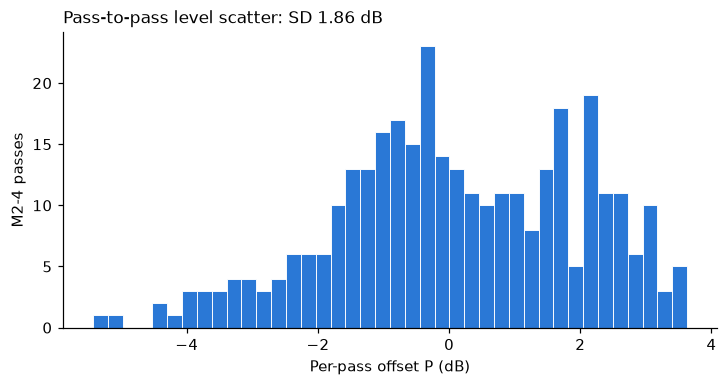

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.4), layout="constrained")
ax.hist(P, bins=40, color="#2a78d6", edgecolor="white", linewidth=0.6)
ax.set_xlabel("Per-pass offset P (dB)")
ax.set_ylabel("M2-4 passes")
ax.set_title(f"Pass-to-pass level scatter: SD {P.std():.2f} dB", fontsize=11, loc="left")
plt.show()

## 4. Propagate the M2-4 deviation into the M2-3 pattern

If `D` is the real in-flight behaviour of M2-4, its gain toward a sample is `G_ref + D`, so the stage-1 calibration sample
should have been `R - D`. The cell below rebuilds the calibration map from the corrected samples and reconstructs M2-3
again with exactly the pipeline's stages 2-3.

`transfer error = baseline - corrected` is the error the published pattern carries from source 4, cell by cell.
`D` is 0 in bins where it is not estimated, so those directions contribute no correction.

In [9]:
t0 = time.time()
baseline = reconstruct_grid(m24, m23)
corrected = reconstruct_grid(m24.assign(rx_response_db=R - np.where(fitted, D, 0.0)[b_code]), m23)
transfer = baseline[GAIN].to_numpy() - corrected[GAIN].to_numpy()
print(f"Two reconstructions in {time.time() - t0:.0f} s")

published = pd.read_csv(OUT_DIR / rp.PATTERN_CSV_NAME)[GAIN].to_numpy()
base = baseline[GAIN].to_numpy()
both = np.isfinite(published) & np.isfinite(base)
max_diff = np.max(np.abs(published[both] - base[both]))
print(
    f"Check vs published {rp.PATTERN_CSV_NAME}: max |difference| {max_diff:.3f} dB "
    "(non-zero only where M2-4 rows without a valid heading were dropped here)"
)

fin = np.isfinite(transfer)
abs_e = np.abs(transfer[fin])
print(
    f"Transfer error over {fin.sum():,} supported cells: median |e| {np.median(abs_e):.2f} dB, "
    f"90th pct |e| {np.percentile(abs_e, 90):.2f} dB, "
    f"cells with |e| > 1 dB: {np.mean(abs_e > 1):.0%}, > 2 dB: {np.mean(abs_e > 2):.0%}"
)

Two reconstructions in 5 s
Check vs published m2_3_antenna_pattern.csv: max |difference| 0.000 dB (non-zero only where M2-4 rows without a valid heading were dropped here)
Transfer error over 19,332 supported cells: median |e| 0.26 dB, 90th pct |e| 1.22 dB, cells with |e| > 1 dB: 15%, > 2 dB: 3%


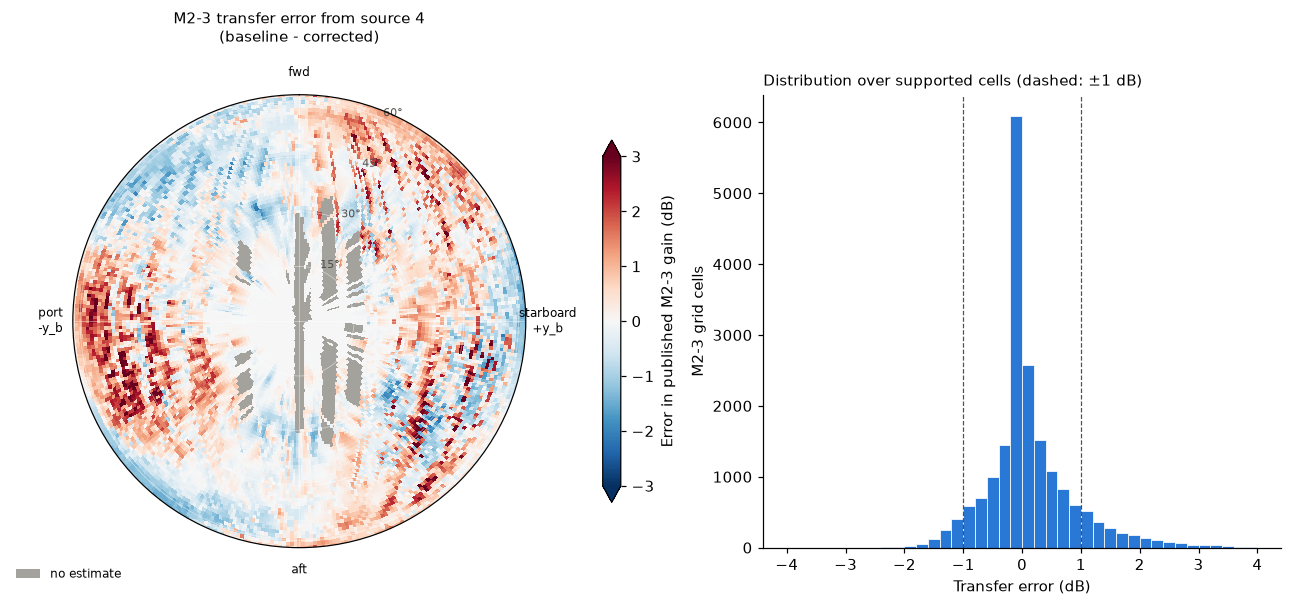

In [10]:
fig = plt.figure(figsize=(12, 5.4), layout="constrained")
ax0 = fig.add_subplot(1, 2, 1, projection="polar")
mesh = polar_map(
    ax0,
    transfer.reshape(N_TH, N_AZ),
    GRID_AZ_EDGES,
    GRID_R_EDGES,
    DIVERGING,
    TwoSlopeNorm(vcenter=0, vmin=-3, vmax=3),
    "M2-3 transfer error from source 4\n(baseline - corrected)",
)
cb = fig.colorbar(mesh, ax=ax0, shrink=0.8, extend="both")
cb.set_label("Error in published M2-3 gain (dB)")
ax0.legend(handles=[MISSING_PATCH], loc="upper left", bbox_to_anchor=(-0.15, -0.02), fontsize=8, frameon=False)

ax1 = fig.add_subplot(1, 2, 2)
ax1.hist(transfer[fin], bins=np.arange(-4, 4.01, 0.2), color="#2a78d6", edgecolor="white", linewidth=0.5)
for x in (-1, 1):
    ax1.axvline(x, color="#52514e", linewidth=0.8, linestyle="--")
ax1.set_xlabel("Transfer error (dB)")
ax1.set_ylabel("M2-3 grid cells")
ax1.set_title("Distribution over supported cells (dashed: ±1 dB)", fontsize=10, loc="left")
plt.show()

## 5. Statistical scatter: bootstrap over passes

Most measured cells are fed by one to three passes, and whole passes move by about ±2 dB (section 3). The bootstrap
resamples passes with replacement, independently for both satellites, re-runs stages 1-3 and takes the per-cell standard
deviation. This is uncertainty source 4's companion: random rather than systematic.

In [11]:
rng = np.random.default_rng(SEED)
rows24, rows23 = m24.groupby("file").indices, m23.groupby("file").indices
names24, names23 = np.array(list(rows24)), np.array(list(rows23))
boot = np.full((N_BOOT, N_TH * N_AZ), np.nan)
t0 = time.time()
for i in range(N_BOOT):
    s24 = np.concatenate([rows24[t] for t in rng.choice(names24, names24.size)])
    s23 = np.concatenate([rows23[t] for t in rng.choice(names23, names23.size)])
    boot[i] = reconstruct_grid(m24.iloc[s24], m23.iloc[s23])[GAIN].to_numpy()
    if (i + 1) % 10 == 0:
        print(f"  {i + 1}/{N_BOOT} replicates ({time.time() - t0:.0f} s)")

n_finite = np.isfinite(boot).sum(axis=0)
sigma = np.full(N_TH * N_AZ, np.nan)
enough = n_finite >= BOOT_MIN_FINITE * N_BOOT
sigma[enough] = np.nanstd(boot[:, enough], axis=0, ddof=1)
sigma[~np.isfinite(baseline[GAIN].to_numpy())] = np.nan
fs = np.isfinite(sigma)
print(
    f"Bootstrap sigma over {fs.sum():,} cells: median {np.median(sigma[fs]):.2f} dB, "
    f"90th pct {np.percentile(sigma[fs], 90):.2f} dB"
)

  10/40 replicates (26 s)
  20/40 replicates (51 s)
  30/40 replicates (76 s)
  40/40 replicates (101 s)
Bootstrap sigma over 14,754 cells: median 1.28 dB, 90th pct 2.58 dB


## 6. Combined per-cell uncertainty

`combined = sqrt(transfer_error² + sigma²)`: the systematic error from the M2-4 deviation (identifiable part) and the
pass-to-pass scatter, added in quadrature. Sources 1-3 would add a common offset to every cell on top of this.

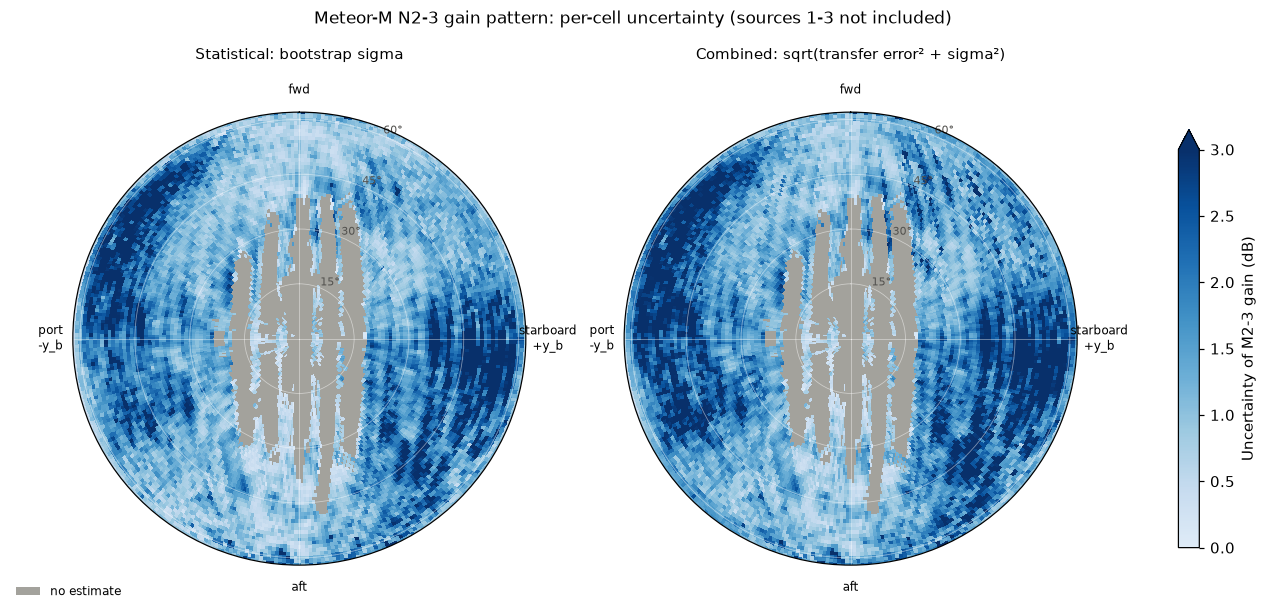

In [12]:
combined = np.sqrt(transfer**2 + sigma**2)
seq = Normalize(vmin=0, vmax=3)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.6), subplot_kw={"projection": "polar"}, layout="constrained")
polar_map(
    axes[0], sigma.reshape(N_TH, N_AZ), GRID_AZ_EDGES, GRID_R_EDGES, SEQUENTIAL, seq, "Statistical: bootstrap sigma"
)
mesh = polar_map(
    axes[1],
    combined.reshape(N_TH, N_AZ),
    GRID_AZ_EDGES,
    GRID_R_EDGES,
    SEQUENTIAL,
    seq,
    "Combined: sqrt(transfer error² + sigma²)",
)
cb = fig.colorbar(mesh, ax=axes, shrink=0.75, extend="max")
cb.set_label("Uncertainty of M2-3 gain (dB)")
axes[0].legend(handles=[MISSING_PATCH], loc="upper left", bbox_to_anchor=(-0.15, -0.02), fontsize=8, frameon=False)
fig.suptitle("Meteor-M N2-3 gain pattern: per-cell uncertainty (sources 1-3 not included)", fontsize=11)
plt.show()

In [13]:
cells = baseline[["azimuth_deg", "off_nadir_deg", GAIN, "sample_count"]].copy()
cells[f"{GAIN}_m24_corrected"] = corrected[GAIN].to_numpy()
cells["transfer_error_db"] = transfer
cells["bootstrap_sigma_db"] = sigma
cells["combined_uncertainty_db"] = combined

band = pd.cut(
    cells["off_nadir_deg"], [0, 15, 30, 45, 62], include_lowest=True, labels=["0-15°", "15-30°", "30-45°", "45-62°"]
)
valid = cells["combined_uncertainty_db"].notna()
summary = (
    cells[valid]
    .groupby(band[valid], observed=True)
    .agg(
        cells=("combined_uncertainty_db", "size"),
        median_abs_transfer_db=("transfer_error_db", lambda s: s.abs().median()),
        median_sigma_db=("bootstrap_sigma_db", "median"),
        median_combined_db=("combined_uncertainty_db", "median"),
        p90_combined_db=("combined_uncertainty_db", lambda s: s.quantile(0.9)),
        share_over_2db=("combined_uncertainty_db", lambda s: (s > 2).mean()),
    )
)
summary.index = summary.index.astype(str)
overall = cells.loc[valid, "combined_uncertainty_db"]
summary.loc["all"] = [
    valid.sum(),
    cells.loc[valid, "transfer_error_db"].abs().median(),
    cells.loc[valid, "bootstrap_sigma_db"].median(),
    overall.median(),
    overall.quantile(0.9),
    (overall > 2).mean(),
]
summary.round(2)

,cells,median_abs_transfer_db,median_sigma_db,median_combined_db,p90_combined_db,share_over_2db
off_nadir_deg,,,,,,
0-15°,981.0,0.00,0.64,0.65,1.06,0.00
15-30°,2697.0,0.20,1.21,1.33,2.19,0.16
30-45°,4967.0,0.41,1.34,1.51,2.75,0.28
45-62°,6109.0,0.58,1.44,1.68,3.31,0.38
all,14754.0,0.38,1.28,1.46,2.92,0.28


**Do the M2-3 findings survive?** Median gain in four body-frame sectors near the edge of coverage (off-nadir 50-62°),
before and after removing the M2-4 deviation, with the median combined uncertainty of those cells.

In [14]:
edge = cells[cells["off_nadir_deg"].between(50, 62)]
az = edge["azimuth_deg"]
sectors = {
    "forward (330-30°)": (az >= 330) | (az <= 30),
    "starboard (60-120°)": az.between(60, 120),
    "aft (150-210°)": az.between(150, 210),
    "port (240-300°)": az.between(240, 300),
}
pd.DataFrame(
    {
        name: {
            f"published ({rp.GAIN_UNIT})": edge.loc[m, GAIN].median(),
            f"M2-4-corrected ({rp.GAIN_UNIT})": edge.loc[m, f"{GAIN}_m24_corrected"].median(),
            "median combined uncertainty (dB)": edge.loc[m, "combined_uncertainty_db"].median(),
        }
        for name, m in sectors.items()
    }
).T.round(2)

,published (dBic),M2-4-corrected (dBic),median combined uncertainty (dB)
forward (330-30°),4.47,4.12,1.12
starboard (60-120°),-2.57,-2.43,2.20
aft (150-210°),-5.51,-5.51,1.24
port (240-300°),-0.56,-1.66,2.56


In [15]:
cells.to_csv(OUT_DIR / "m2_3_gain_uncertainty.csv", index=False, float_format="%.4f")
bin_info[
    [
        "off_nadir_center_deg",
        "azimuth_center_deg",
        "deviation_db",
        "holdout_residual_db",
        "n_samples",
        "n_tracks",
        "fitted",
    ]
].sort_values(["off_nadir_center_deg", "azimuth_center_deg"]).to_csv(
    OUT_DIR / "m24_deviation_map.csv", index=False, float_format="%.4f"
)
print("Wrote", OUT_DIR / "m2_3_gain_uncertainty.csv")
print("Wrote", OUT_DIR / "m24_deviation_map.csv")

Wrote m2_3_pattern_output/m2_3_gain_uncertainty.csv
Wrote m2_3_pattern_output/m24_deviation_map.csv


### Reading the results

* **`m2_3_gain_uncertainty.csv`** — one row per output-grid cell: published gain, gain after removing the M2-4
  deviation, `transfer_error_db`, `bootstrap_sigma_db` and `combined_uncertainty_db`.
  `<gain>_m24_corrected` is a better point estimate *if* `D` is right; the published CSV is left unchanged.
* **`m24_deviation_map.csv`** — the M2-4 deviation `D` and the model-free hold-out residual on 10° × 2° body-frame bins.
* The statistical part (pass-to-pass scatter) is larger than the systematic transfer error in most cells: most measured
  cells rest on one to three passes.
* The forward/aft asymmetry of M2-3 survives the correction, because M2-4 shows almost no forward/aft deviation. The
  port/starboard difference of M2-3 largely does not: M2-4 sees the same sky directions from the same body directions, so
  its port-side deficit lands on M2-3's port side.
* The transfer error is a **lower bound** for source 4 (section 3): axisymmetric reference errors and deviations that look
  the same from ascending and descending passes are invisible to this data and pass straight into M2-3.
* `D` is not estimated below 10° off-nadir, so the 0-15° band's transfer error reads ~0 by construction (not assessed).
* Cells with a bootstrap value in fewer than half of the replicates (the least-supported edges of coverage) get no
  `bootstrap_sigma_db` or `combined_uncertainty_db`; treat them as poorly constrained.
* A port/starboard swing needing a boresight tilt of tens of degrees (table in section 3) is not a plausible pointing
  error. It points to a genuinely non-axisymmetric in-flight M2-4 pattern (e.g. spacecraft structure near the antenna) or
  polarisation effects between the satellite and the ground antenna.